# MNIST: CNN versus Fully Connected Networks

**Author:** Mohammed Alaa Eddine GUERBOUZ  
**University:** University of Ghardaia — Department of Mathematics and Computer Science  
**Academic period:** Master 2 SIEC · 2024–2025  
**Type:** Original university coursework, reorganized for a GitHub portfolio in 2026

**Problem:** Classify handwritten digits and compare convolutional and dense neural networks.

**Approach:** TensorFlow/Keras CNN and FCNN implementations.

> Historical coursework: the computational cells below are retained from the original submission. Results have not been independently rerun or revalidated as part of the portfolio reorganization. See this folder's README for data and execution notes.


---

<div class="alert alert-success">

<center><b>University of Ghardaia</b></center>
    
<center><i>Faculty of Science and Technology - Department of Mathematics and Computer Science – Master 2 SIEC - 2024/2025</i>
</center></div>

------

<br><br>

<center>
<span style='font-weight:bold;font-size:27px;'><span style='color:#5D00FF;'>Mini Project  : Part 1 Project 1 CNN </span>
    </span>
    </center>
<br>


# TP 1 AI USING CNN
## GUERBOUZ MOHAMMED ALAA EDDINE

In [2]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Dropout,Activation,Flatten,Conv2D,MaxPooling2D
import cv2 

# Loading " MNIST DATASETS "
## Contains 60k Training samples  , 10k  Testing Samples
### it is in the Metadata of the tensorFlow Library and Exactly from keras

In [8]:
mnist = tf.keras.datasets.mnist

## After Loading The MNIST data , Divide it into train and test datasets

In [38]:
(X_train,Y_train),(X_test,Y_test) = mnist.load_data()

### Stats of the datset

In [42]:
print("Training data shape:", X_train.shape)  # (60000, 28, 28)
print("Training labels shape:", Y_train.shape)  # (60000,)
print("Test data shape:", X_test.shape)  # (10000, 28, 28)
print("Test labels shape:", Y_test.shape)  # (10000,)
print("Number of classes:", len(set(Y_train)))  # 10
import numpy as np
print("Class distribution in training set:", np.bincount(Y_train))
print("Class distribution in test set:", np.bincount(Y_test))

Training data shape: (60000, 28, 28)
Training labels shape: (60000,)
Test data shape: (10000, 28, 28)
Test labels shape: (10000,)
Number of classes: 10
Class distribution in training set: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]
Class distribution in test set: [ 980 1135 1032 1010  982  892  958 1028  974 1009]


In [10]:
X_train.shape

(60000, 28, 28)

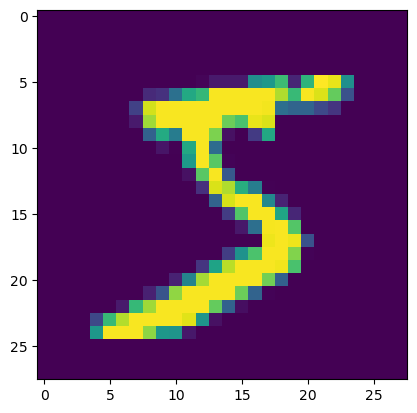

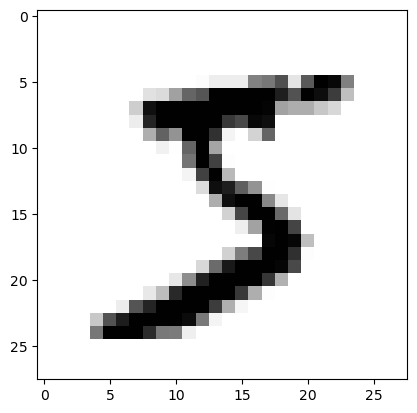

In [11]:
plt.imshow(X_train[0])
plt.show()
plt.imshow(X_train[0],cmap=plt.cm.binary)

## Checking the value of each pixels before normalization

In [12]:
print(X_train[0])

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  82  56  39   0   0   0   0   0]
 [  0   0   0   0   0   0   0  18 219 253 253 253 253 253 198 18

## As image are in gray level 1(channel ==> 0 to 225) not colored (RGB)
# Normalizing The Data | Pre-Processing Step

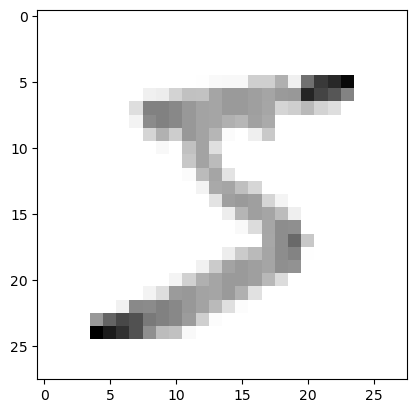

In [13]:
X_train = tf.keras.utils.normalize (X_train, axis=1)
X_test = tf.keras.utils.normalize  (X_test , axis=1)
plt.imshow(X_train[0], cmap = plt.cm.binary)

# After Normalization

## Resizing Image to make it suitable for apply Convenotional Operations

In [14]:
img_size= 28
x_trainer =np.array(X_train).reshape(-1,img_size,img_size,1)
x_tester = np.array(X_test).reshape(-1,img_size,img_size,1)
print("training sample dimension",x_trainer.shape)
print("testing sample dimension",x_tester.shape)

training sample dimension (60000, 28, 28, 1)
testing sample dimension (10000, 28, 28, 1)


# Creating The Deep Neural Networks


In [43]:
#Creat a neural network Now

#------------------------------------------------------
### first Convolution Layer 0 1 2 3 (60000,28,28,1)
model = Sequential()
model.add(Conv2D(64,(3,3),input_shape = x_trainer.shape[1:])) # only for first Convlution layer  to mention input Layer Size 
model.add(Activation("relu"))# Activvation function to make it non linear ,
model.add(MaxPooling2D(pool_size=(2)))##MaxPooling single maximum values oif 2x2
#------------------------------------------------------
### Seconde Convolution Layer
model.add(Conv2D(64,(3,3)))
model.add(Activation("relu")) 
model.add(MaxPooling2D(pool_size=(2))) 
#------------------------------------------------------
#------------------------------------------------------
### Third Convolution Layer
model.add(Conv2D(64,(3,3))) # 24 x 24
model.add(Activation("relu"))
model.add(MaxPooling2D(pool_size=(2)))

#------------------------------------------------------
### Fully Connected Layer #1 20x20 =400
model.add(Flatten()) # Before using the fully Connected layer  need to be flatten so that 2d to 1d
model.add(Dense(64)) # 
model.add(Activation("relu"))

### Fully Connected Layer #2
model.add(Dense(32))
model.add(Activation("relu"))
### last Fully Connected Layer #3 , output must  be equal to number of classes , 10(0-9)
model.add(Dense(10)) # This last danse layer must be equal to 10
model.add(Activation('softmax')) #Activation function is changed to softmax '(Class Probabilities) 
#Binary classification , one neuron is Danse Layer ,sigmoid

In [44]:
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_3 (Conv2D)           (None, 26, 26, 64)        640       
                                                                 
 activation_6 (Activation)   (None, 26, 26, 64)        0         
                                                                 
 max_pooling2d_3 (MaxPoolin  (None, 13, 13, 64)        0         
 g2D)                                                            
                                                                 
 conv2d_4 (Conv2D)           (None, 11, 11, 64)        36928     
                                                                 
 activation_7 (Activation)   (None, 11, 11, 64)        0         
                                                                 
 max_pooling2d_4 (MaxPoolin  (None, 5, 5, 64)          0         
 g2D)                                                 

In [17]:
model.compile(loss="sparse_categorical_crossentropy",optimizer="adam",metrics=['accuracy'])

## training my model 

In [18]:
model.fit(x_trainer,Y_train,epochs=7,validation_split=0.3) 

Epoch 1/7
1313/1313 [==============================] - 22s 16ms/step - loss: 0.3081 - accuracy: 0.9039 - val_loss: 0.1191 - val_accuracy: 0.9626
Epoch 2/7
1313/1313 [==============================] - 21s 16ms/step - loss: 0.0999 - accuracy: 0.9692 - val_loss: 0.1146 - val_accuracy: 0.9651
Epoch 3/7
1313/1313 [==============================] - 26s 20ms/step - loss: 0.0745 - accuracy: 0.9768 - val_loss: 0.0845 - val_accuracy: 0.9740
Epoch 4/7
1313/1313 [==============================] - 28s 21ms/step - loss: 0.0599 - accuracy: 0.9819 - val_loss: 0.0939 - val_accuracy: 0.9715
Epoch 5/7
1313/1313 [==============================] - 32s 24ms/step - loss: 0.0482 - accuracy: 0.9843 - val_loss: 0.0624 - val_accuracy: 0.9814
Epoch 6/7
1313/1313 [==============================] - 33s 25ms/step - loss: 0.0396 - accuracy: 0.9871 - val_loss: 0.0709 - val_accuracy: 0.9785
Epoch 7/7
1313/1313 [==============================] - 32s 25ms/step - loss: 0.0336 - accuracy: 0.9886 - val_loss: 0.0610 - val_ac

## Evaluating on testing data set MNIT 

In [19]:
test_loss ,test_acc =model.evaluate(x_tester,Y_test)
print("Test Loss on 10,000 test sample",test_loss)
print("Validation Accuracy on 10,000 test sample",test_acc)

313/313 [==============================] - 1s 4ms/step - loss: 0.0584 - accuracy: 0.9830
Test Loss on 10,000 test sample 0.05841267853975296
Validation Accuracy on 10,000 test sample 0.9829999804496765


## Predict the X_test partt from the divided dataset

In [20]:
predections=model.predict([x_tester])

313/313 [==============================] - 1s 4ms/step


In [21]:
print(predections)

[[1.2451093e-07 9.4126744e-07 1.3092887e-05 ... 9.9998379e-01
  6.6005557e-09 9.1088447e-07]
 [6.0493421e-05 5.8475980e-09 9.9993181e-01 ... 1.8214833e-07
  3.6671922e-06 2.4337903e-09]
 [4.3655842e-07 9.9999881e-01 3.1269337e-07 ... 1.0442468e-07
  3.2169162e-08 1.1673965e-08]
 ...
 [5.1329225e-09 3.6337195e-08 1.0243807e-08 ... 5.2397066e-08
  1.1774766e-07 4.5280590e-06]
 [2.8694480e-10 1.3412307e-13 4.3093692e-13 ... 1.6368906e-10
  1.5970878e-07 7.9273493e-10]
 [4.1661067e-05 2.4697386e-10 1.3606987e-06 ... 1.7987026e-09
  3.0725055e-06 2.1323264e-07]]


In [22]:
print(np.argmax(predections[128]))

8


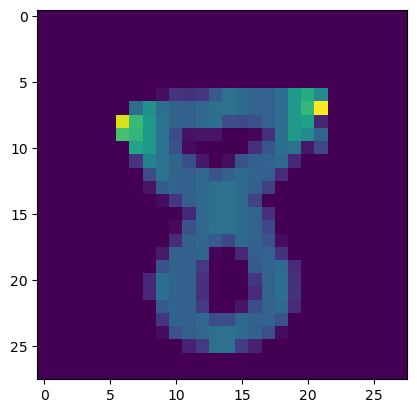

In [23]:
plt.imshow(X_test[128])

## Download the Image to be tested out by the model its dimension is 28x28

In [26]:
img = cv2.imread('test.Png')

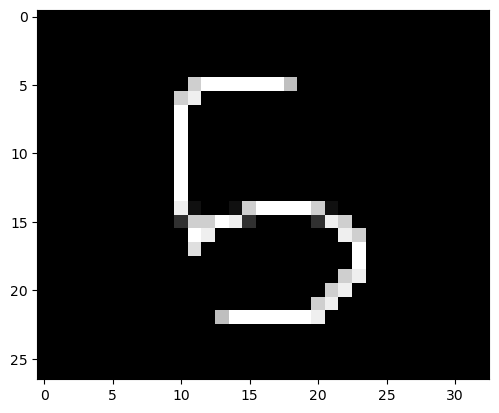

In [27]:
plt.imshow(img)

### As image are in gray level 1(channel ==> 0 to 225) not colored (RGB)
## Normalizing The Image | Pre-Processing Step

In [28]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

resized = cv2.resize(gray,(28,28), interpolation =cv2.INTER_AREA)

In [29]:
newimg =tf.keras.utils.normalize(resized, axis=1)

## Resizing the image

In [30]:
newimg = np.array(newimg).reshape(-1,28,28,1)

## Make predictions

In [31]:
p= model.predict(newimg)

1/1 [==============================] - 0s 70ms/step


## The prediction result

In [32]:
print(np.argmax(p))

5
